# 2nd-order Chebyshev low-pass (Sallen-Key) - measured frequency response

**Data used:** the 100 Hz - 100 kHz sine sweep (`data/bode_measurements_raw.csv`), the only valid measurement.
The impulse/pulse captures contain no signal (noise only) and are **not** used as measurements. Section 8 shows why.

**Corrections applied to the raw sweep (documented, reversible):**
1. **CH1/CH2 are swapped.** The column `vin_v` falls with frequency and `vout_v` is flat, so the "input" channel is physically the filter output. We therefore use `gain = vin_v / vout_v` and flip the sign of the phase.
2. **Probe scale** (amplitudes ~10-20x too large) cancels in the gain ratio, so gain and phase are unaffected.
3. **Above 10 kHz the output sits on the scope noise floor** (~0.6 V in these units) and the fitted amplitudes are not valid. Those rows are flagged `valid = False` and drawn hollow.

Anything labelled *simulated* or *reconstructed* is not raw scope data.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy.optimize import least_squares
from theory import DESIGN, PRACTICAL, transfer_function, response

Path("figures").mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "figure.autolayout": True})
VALID_MAX_HZ = 10_000      # above this the output is at the noise floor

## 1. Corrected dataset

In [2]:
raw = pd.read_csv("data/bode_measurements_raw.csv")

df = pd.DataFrame({
    "frequency_hz": raw.frequency_hz,
    "v_in_true_raw_units":  raw.vout_v,           # swapped: generator side
    "v_out_true_raw_units": raw.vin_v,            # swapped: filter output
    "gain": raw.vin_v / raw.vout_v,
})
df["gain_db"] = 20*np.log10(df.gain)
df["phase_deg"] = (-raw.phase_deg + 180) % 360 - 180      # sign flip (output lags)
df["valid"] = df.frequency_hz <= VALID_MAX_HZ
df.to_csv("data/bode_measurements_corrected.csv", index=False)
v = df[df.valid]; inv = df[~df.valid]
df.round(4)

,frequency_hz,v_in_true_raw_units,v_out_true_raw_units,gain,gain_db,phase_deg,valid
0,100.0,5.0166,10.0565,2.0046,6.0407,-1.0516,True
1,200.0,5.0207,10.0310,1.9979,6.0117,-1.8740,True
2,300.0,4.9994,10.0528,2.0108,6.0673,-3.0449,True
3,400.0,4.9941,10.0600,2.0144,6.0827,-4.1814,True
4,500.0,4.9909,10.0921,2.0221,6.1161,-5.0973,True
5,600.0,4.9952,10.1051,2.0230,6.1197,-6.1993,True
6,700.0,4.9974,10.1345,2.0279,6.1411,-7.2570,True
7,800.0,4.9995,10.1458,2.0294,6.1472,-8.2829,True
8,900.0,5.0010,10.1930,2.0382,6.1849,-9.1004,True
9,1000.0,4.9914,10.2273,2.0490,6.2307,-10.5157,True


## 2. Fit the measured magnitude (K and f0)
Equal-component Sallen-Key: `H = K w0^2 / (s^2 + (3-K) w0 s + w0^2)`, free parameters `K` and `f0`. Magnitude only, valid points only.

In [3]:
def model(p, f):
    K, f0 = p
    w0 = 2*np.pi*f0; s = 2j*np.pi*np.asarray(f, float)
    return K*w0**2/(s*s + (3-K)*w0*s + w0**2)

fit = least_squares(lambda p: 20*np.log10(abs(model(p, v.frequency_hz))) - v.gain_db,
                    [1.7, 5700], bounds=([1, 1000], [2.99, 20000]))
K_fit, f0_fit = fit.x
Q_fit = 1/(3-K_fit)
rms = np.sqrt(np.mean(fit.fun**2))
print(f"Fitted K  = {K_fit:.3f}  ({20*np.log10(K_fit):.2f} dB)   -> implied Rf/Rg = {K_fit-1:.3f}")
print(f"Fitted f0 = {f0_fit:.0f} Hz   Q = {Q_fit:.3f}")
print(f"RMS magnitude error of fit: {rms:.3f} dB")
print()
print(f"Design    : K = {1+DESIGN['Rf']/10e3:.3f}, f0 = {1/(2*np.pi*DESIGN['R']*10e-9):.0f} Hz")
print(f"Practical : K = {1+PRACTICAL['Rf']/10e3:.3f}, f0 = {1/(2*np.pi*PRACTICAL['R']*10e-9):.0f} Hz")

Fitted K  = 2.024  (6.12 dB)   -> implied Rf/Rg = 1.024
Fitted f0 = 5491 Hz   Q = 1.024
RMS magnitude error of fit: 0.091 dB

Design    : K = 1.689, f0 = 5648 Hz
Practical : K = 1.680, f0 = 5684 Hz


**Reading:** the measured magnitude is matched to ~0.1 dB by `K ~ 2.0`, `f0 ~ 5.5 kHz`, `Q ~ 1.0`, whereas the design has `K = 1.68`, `Q = 0.76`.
That is consistent with **Rf/Rg being about 1 instead of 0.68** (a different/mis-valued gain resistor or Rf not 6.8 kOhm). This is a hypothesis: **measure Rf and Rg with a multimeter on Friday** to confirm.
It explains the passband sitting ~1.5 dB above theory and the 1.5 dB peaking near 4 kHz (a real Chebyshev 1 % ripple would be only 0.04 dB).

## 3. Key frequencies: cutoff, peak, roll-off

In [4]:
fg = np.logspace(2, 5, 6000)

def minus3db(gain_db, f, ref_db):
    # first downward crossing of (ref - 3 dB) after the peak, log-frequency interpolation
    i0 = np.argmax(gain_db)
    level = ref_db - 3
    for i in range(i0, len(f)-1):
        if gain_db[i] >= level > gain_db[i+1]:
            x = (level-gain_db[i])/(gain_db[i+1]-gain_db[i])
            return 10**(np.log10(f[i]) + x*(np.log10(f[i+1])-np.log10(f[i])))
    return np.nan

rows = []
# measured (valid points only, relative to mean passband gain 100 Hz - 1 kHz)
ref_meas = v[v.frequency_hz <= 1000].gain_db.mean()
ipk = v.gain_db.idxmax()
rows.append(["Measured", ref_meas, v.loc[ipk, "frequency_hz"], v.loc[ipk, "gain_db"] - ref_meas,
             minus3db(v.gain_db.values, v.frequency_hz.values, ref_meas)])
for name, p in [("Fit (K,f0)", None), ("Theory - implemented R,Rf", PRACTICAL), ("Theory - design R,Rf", DESIGN)]:
    H = model((K_fit, f0_fit), fg) if p is None else transfer_function(fg, p["R"], p["Rf"])
    g = 20*np.log10(abs(H))
    ref = g[0]
    rows.append([name, ref, fg[np.argmax(g)], g.max()-ref, minus3db(g, fg, ref)])

keyf = pd.DataFrame(rows, columns=["source", "passband_gain_dB", "peak_freq_Hz", "peaking_dB", "minus3dB_cutoff_Hz"]).round(2)
keyf.to_csv("data/key_frequencies.csv", index=False)
keyf

,source,passband_gain_dB,peak_freq_Hz,peaking_dB,minus3dB_cutoff_Hz
0,Measured,6.11,4000.00,1.44,7076.04
1,"Fit (K,f0)",6.12,3974.35,1.39,7052.53
2,"Theory - implemented R,Rf",4.51,2040.41,0.07,6054.65
3,"Theory - design R,Rf",4.55,2121.88,0.09,6052.62


In [5]:
# Local roll-off slope between consecutive valid points (dB/decade). 2nd order -> -40 dB/dec asymptotically.
vv = v[v.frequency_hz >= 4000].reset_index(drop=True)
slope = pd.DataFrame({
    "from_Hz": vv.frequency_hz[:-1].values, "to_Hz": vv.frequency_hz[1:].values,
    "slope_dB_per_decade": (np.diff(vv.gain_db) / np.diff(np.log10(vv.frequency_hz))).round(1),
})
slope.to_csv("data/rolloff_slopes.csv", index=False)
print("Asymptotic theory: -40 dB/decade (= -12 dB/octave)")
slope

Asymptotic theory: -40 dB/decade (= -12 dB/octave)


,from_Hz,to_Hz,slope_dB_per_decade
0,4000.0,5000.0,-4.6
1,5000.0,6000.0,-19.5
2,6000.0,7000.0,-33.9
3,7000.0,8000.0,-38.3
4,8000.0,9000.0,-45.9
5,9000.0,10000.0,-46.4


The local slope steepens towards -40 dB/decade as frequency rises. We can only measure it up to 10 kHz because of the noise floor above that, so the final -40 dB/decade asymptote is verified from the fit/theory rather than from this dataset. **Re-measure above 10 kHz on Friday with proper vertical scaling.**

## 4. Bode magnitude

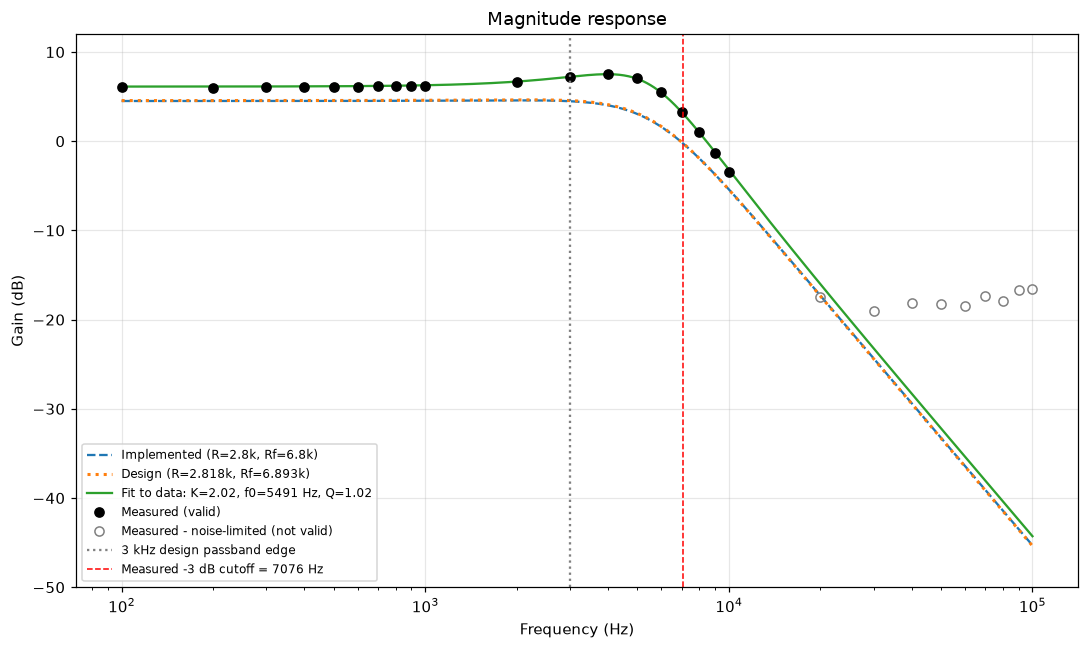

In [6]:
ff = np.logspace(2, 5, 1000)
fig, ax = plt.subplots(figsize=(10, 6))
ax.semilogx(ff, response(ff, PRACTICAL)[0], "--", label=PRACTICAL["label"])
ax.semilogx(ff, response(ff, DESIGN)[0], ":", lw=2, label=DESIGN["label"])
ax.semilogx(ff, 20*np.log10(abs(model((K_fit, f0_fit), ff))), "-", lw=1.5,
            label=f"Fit to data: K={K_fit:.2f}, f0={f0_fit:.0f} Hz, Q={Q_fit:.2f}")
ax.semilogx(v.frequency_hz, v.gain_db, "o", color="k", label="Measured (valid)")
ax.semilogx(inv.frequency_hz, inv.gain_db, "o", mfc="none", color="gray", label="Measured - noise-limited (not valid)")
cut = keyf.loc[0, "minus3dB_cutoff_Hz"]
ax.axvline(3000, color="gray", ls=":", label="3 kHz design passband edge")
ax.axvline(cut, color="r", ls="--", lw=1, label=f"Measured -3 dB cutoff = {cut:.0f} Hz")
ax.set(xlabel="Frequency (Hz)", ylabel="Gain (dB)", title="Magnitude response", ylim=(-50, 12))
ax.legend(fontsize=8, loc="lower left")
fig.savefig("figures/bode_magnitude.png", dpi=200)

## 5. Bode phase

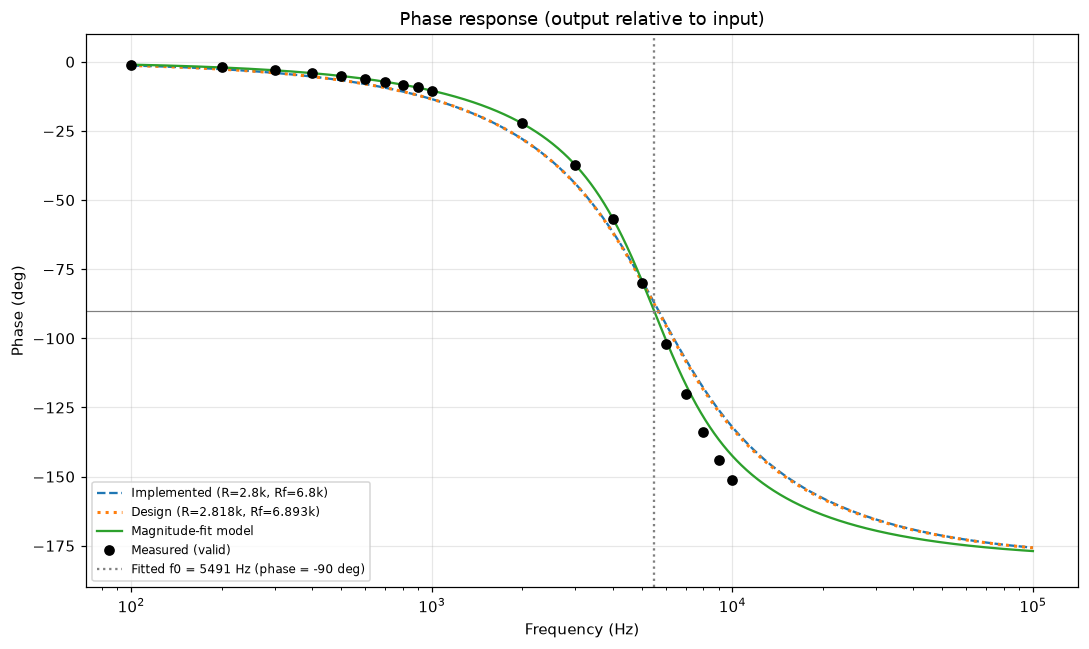

In [7]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.semilogx(ff, response(ff, PRACTICAL)[1], "--", label=PRACTICAL["label"])
ax.semilogx(ff, response(ff, DESIGN)[1], ":", lw=2, label=DESIGN["label"])
ax.semilogx(ff, np.degrees(np.unwrap(np.angle(model((K_fit, f0_fit), ff)))), "-", label="Magnitude-fit model")
ax.semilogx(v.frequency_hz, v.phase_deg, "o", color="k", label="Measured (valid)")
ax.axhline(-90, color="gray", lw=.8)
ax.axvline(f0_fit, color="gray", ls=":", label=f"Fitted f0 = {f0_fit:.0f} Hz (phase = -90 deg)")
ax.set(xlabel="Frequency (Hz)", ylabel="Phase (deg)", title="Phase response (output relative to input)", ylim=(-190, 10))
ax.legend(fontsize=8, loc="lower left")
fig.savefig("figures/bode_phase.png", dpi=200)

Measured phase follows the models up to ~5 kHz and then lags up to ~8 degrees more than the magnitude-fit model near 10 kHz. That extra lag is plausible from op-amp bandwidth, probe/cable loading and the scope's own channel delay, none of which are in the ideal model.

## 6. Roll-off

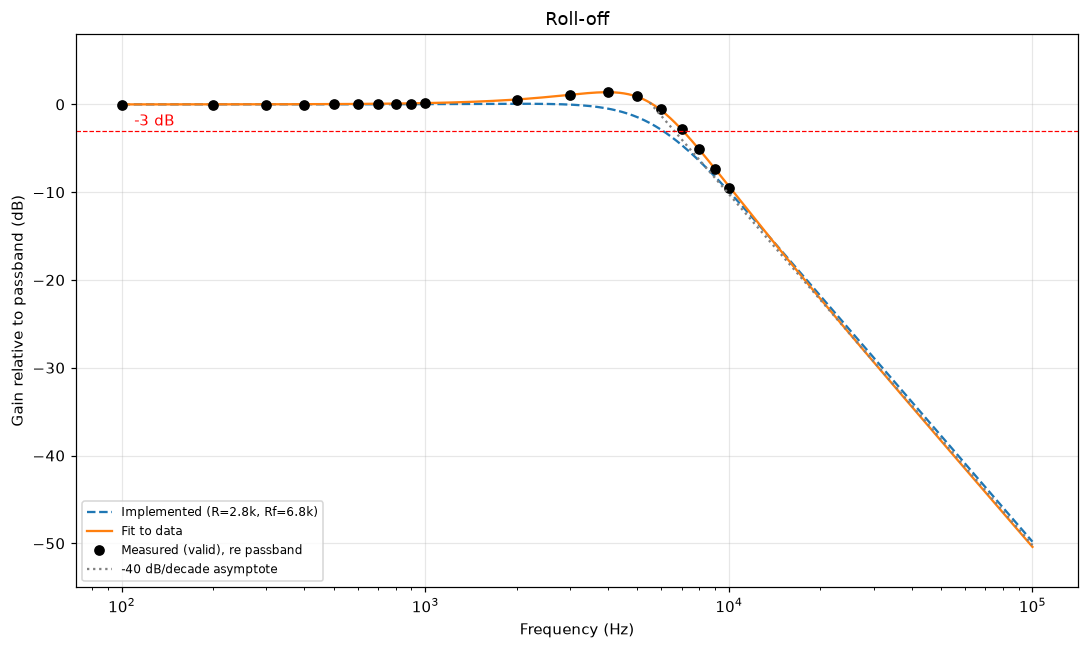

In [8]:
fig, ax = plt.subplots(figsize=(10, 6))
rel = lambda g: g - g[0]
ax.semilogx(ff, rel(response(ff, PRACTICAL)[0]), "--", label=PRACTICAL["label"])
g_fit = 20*np.log10(abs(model((K_fit, f0_fit), ff)))
ax.semilogx(ff, g_fit - g_fit[0], label="Fit to data")
ax.semilogx(v.frequency_hz, v.gain_db - ref_meas, "o", color="k", label="Measured (valid), re passband")
# -40 dB/decade guide anchored at the fitted f0
fa = np.logspace(np.log10(f0_fit), 5, 50)
ax.semilogx(fa, -40*np.log10(fa/f0_fit) + 20*np.log10(Q_fit), color="gray", ls=":", label="-40 dB/decade asymptote")
ax.axhline(-3, color="r", lw=.8, ls="--"); ax.text(110, -2.4, "-3 dB", color="r")
ax.set(xlabel="Frequency (Hz)", ylabel="Gain relative to passband (dB)", title="Roll-off", ylim=(-55, 8))
ax.legend(fontsize=8, loc="lower left")
fig.savefig("figures/rolloff.png", dpi=200)

## 7. How the signal changes with frequency
**Reconstructed** (not raw scope traces): the sweep stored only the fitted amplitude and phase per frequency, so these waveforms are rebuilt from them with a unit-amplitude input.

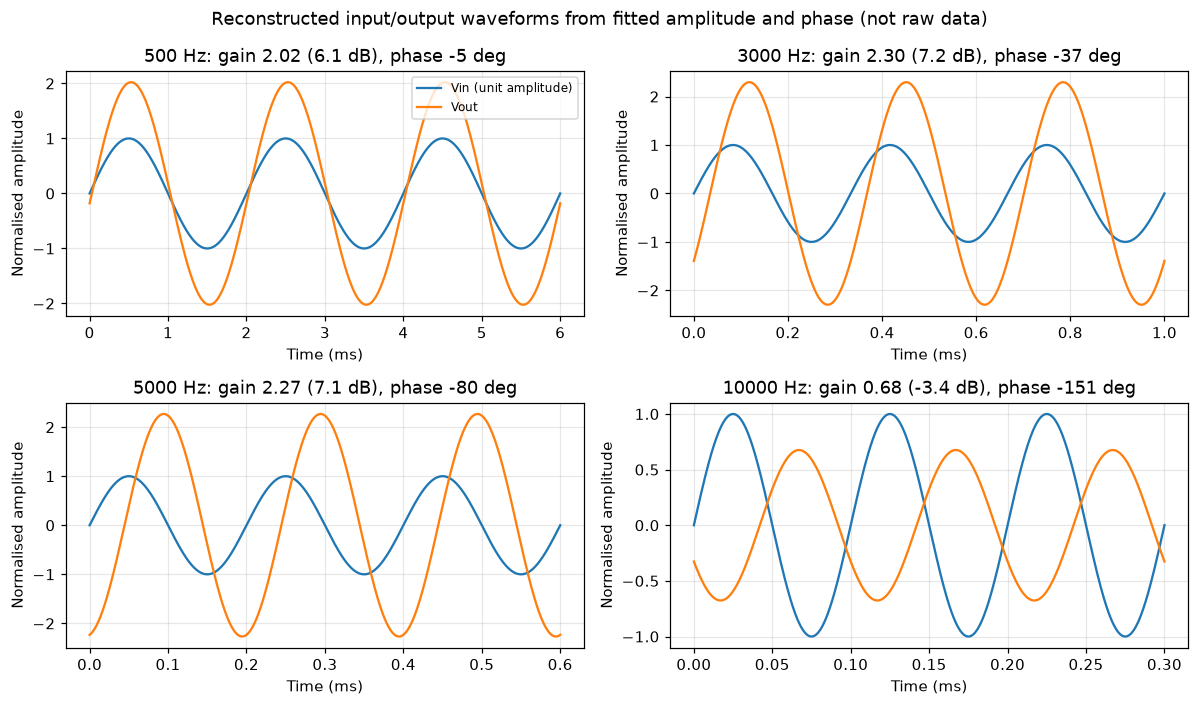

In [9]:
pick = [500, 3000, 5000, 10000]
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
for ax, f in zip(axes.flat, pick):
    r = v[v.frequency_hz == f].iloc[0]
    t = np.linspace(0, 3/f, 800)
    ax.plot(t*1e3, np.sin(2*np.pi*f*t), label="Vin (unit amplitude)")
    ax.plot(t*1e3, r.gain*np.sin(2*np.pi*f*t + np.radians(r.phase_deg)), label="Vout")
    ax.set(title=f"{f} Hz: gain {r.gain:.2f} ({r.gain_db:.1f} dB), phase {r.phase_deg:.0f} deg",
           xlabel="Time (ms)", ylabel="Normalised amplitude")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Reconstructed input/output waveforms from fitted amplitude and phase (not raw data)")
fig.savefig("figures/signal_changes_reconstructed.png", dpi=200)

## 8. FFT and identifying frequencies
**Simulated** (not measured): the 5 kHz, 3 Vpp, 40 ns pulse train used in the impulse experiment, passed through the *fitted* filter, with a one-period FFT like the experiment would take (bins every 5 kHz).

Each input harmonic is only ~1.50 mV: a 40 ns pulse carries very little energy per line.


,harmonic,freq_Hz,Vin_mV,Vout_mV,gain_dB
0,1,5000,1.5,3.354,6.99
1,2,10000,1.5,1.039,-3.19
2,3,15000,1.5,0.434,-10.77
3,4,20000,1.5,0.238,-16.00
4,5,25000,1.5,0.150,-19.99
5,6,30000,1.5,0.103,-23.23
6,7,35000,1.5,0.076,-25.94
7,8,40000,1.5,0.058,-28.29
8,9,45000,1.5,0.046,-30.35
9,10,50000,1.5,0.037,-32.20


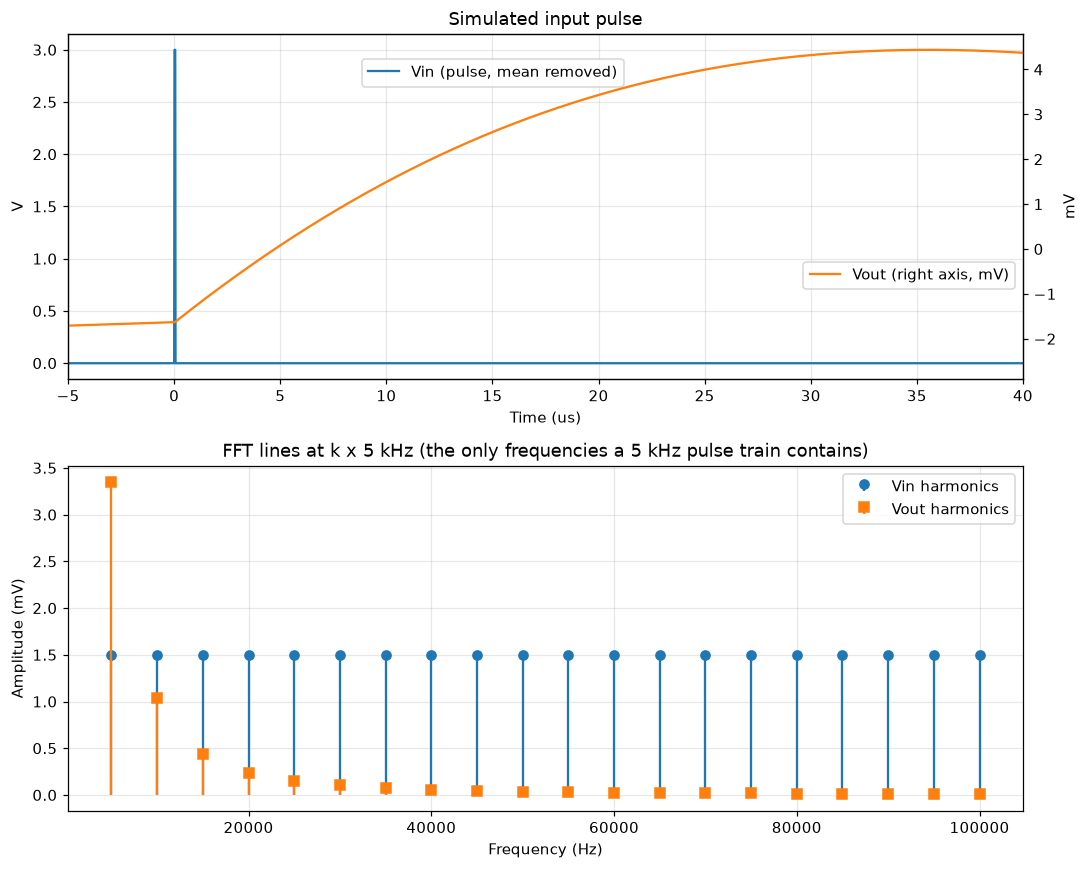

In [10]:
fs_dt = 2e-9; T = 1/5000; N = int(round(T/fs_dt))          # one 200 us period, 2 ns samples (as on the scope)
t = np.arange(N)*fs_dt
A, w, e = 3.0, 40e-9, 10e-9                               # Vpp, width, edges (README settings)
t0 = 50e-6
pulse = np.interp(t, [t0, t0+e, t0+e+w, t0+2*e+w], [0, A, A, 0], left=0, right=0)
pulse -= pulse.mean()
f = np.fft.rfftfreq(N, fs_dt)
Vin = np.fft.rfft(pulse); Vout = Vin*model((K_fit, f0_fit), np.maximum(f, 1e-9))
vout = np.fft.irfft(Vout, N)

k = np.arange(1, 21)
amp_in = 2*np.abs(Vin[k])/N*1e3; amp_out = 2*np.abs(Vout[k])/N*1e3   # mV single-sided
harm = pd.DataFrame({"harmonic": k, "freq_Hz": k*5000, "Vin_mV": amp_in.round(3),
                     "Vout_mV": amp_out.round(3), "gain_dB": (20*np.log10(amp_out/amp_in)).round(2)})
harm.to_csv("data/simulated_pulse_harmonics.csv", index=False)

fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 8))
a1.plot((t-t0)*1e6, pulse, label="Vin (pulse, mean removed)")
a1.set(xlim=(-5, 40), xlabel="Time (us)", ylabel="V", title="Simulated input pulse"); a1.legend(loc="upper left", bbox_to_anchor=(0.3, 0.95))
a1b = a1.twinx(); a1b.plot((t-t0)*1e6, vout*1e3, "C1", label="Vout (right axis, mV)"); a1b.set_ylabel("mV"); a1b.legend(loc="center right", bbox_to_anchor=(1, 0.3)); a1b.grid(False)
a2.stem(k*5000, amp_in, linefmt="C0-", markerfmt="C0o", basefmt=" ", label="Vin harmonics")
a2.stem(k*5000, amp_out, linefmt="C1-", markerfmt="C1s", basefmt=" ", label="Vout harmonics")
a2.set(xlabel="Frequency (Hz)", ylabel="Amplitude (mV)", title="FFT lines at k x 5 kHz (the only frequencies a 5 kHz pulse train contains)")
a2.legend()
fig.savefig("figures/fft_pulse_simulation.png", dpi=200)
print(f"Each input harmonic is only ~{amp_in[0]:.2f} mV: a 40 ns pulse carries very little energy per line.")
harm.head(10)

**Identified frequencies:** a 5 kHz pulse train only has spectral lines at 5, 10, 15, ... kHz. That is why the pulse method can give at most ~20 Bode points up to 100 kHz and why those few lines sit near the 5.5 kHz natural frequency. Each line is only ~1 mV before the filter, which is at the noise floor of the scope. **The impulse method needs averaging or a longer/wider pulse to work.**

### Why the existing impulse captures are not usable (appendix)

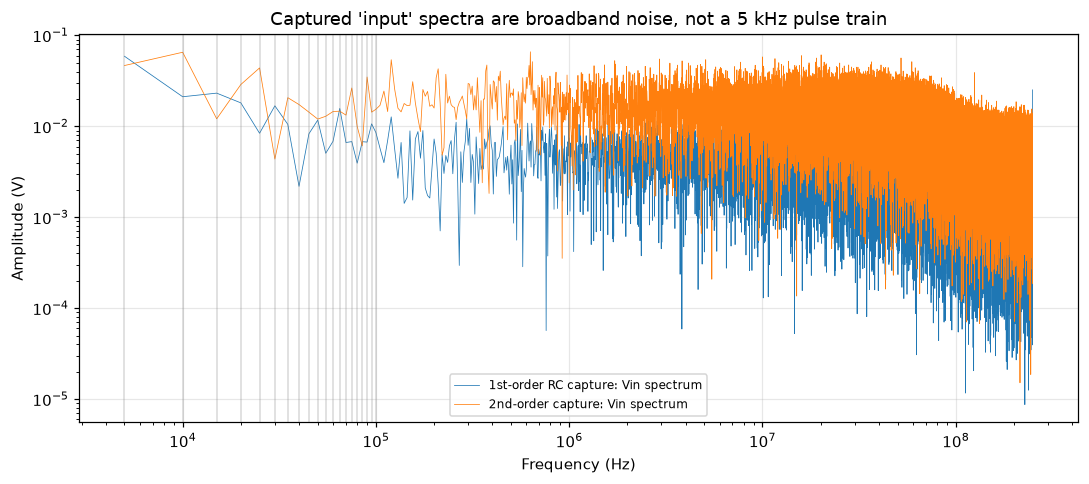

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for path, lab in [("../results/rc_pulse_response_20261113_120155.csv", "1st-order RC capture"),
                  ("../2nd_order/impulse/results/rc_pulse_response_20261113_130603.csv", "2nd-order capture")]:
    d = np.loadtxt(path, delimiter=",", skiprows=1)
    x = d[:, 1]-d[:, 1].mean()
    X = 2*np.abs(np.fft.rfft(x))/len(x)
    fq = np.fft.rfftfreq(len(x), np.diff(d[:, 0]).mean())
    ax.loglog(fq[1:], X[1:], lw=.5, label=f"{lab}: Vin spectrum")
for kk in range(1, 21): ax.axvline(5000*kk, color="gray", lw=.3)
ax.set(xlabel="Frequency (Hz)", ylabel="Amplitude (V)", title="Captured 'input' spectra are broadband noise, not a 5 kHz pulse train")
ax.legend(fontsize=8)
fig.savefig("figures/appendix_failed_impulse_captures.png", dpi=200)

A true pulse train would show clean lines at multiples of 5 kHz (grey) standing out of the floor. The captures show a flat noise floor with no such structure, so no transfer function can be extracted.

## 9. Summary and limits
* Measured response (valid up to 10 kHz) shows a low-pass with a ~6 dB passband, a small peak near 4 kHz and a -3 dB cutoff near 7 kHz (see `data/key_frequencies.csv`).
* Roll-off steepens towards -40 dB/decade; verified only up to 10 kHz in this dataset.
* Measured gain/peaking disagrees with the design (K 1.68 -> fitted ~2.0). Hypothesis: gain resistor ratio. **To check on Friday.**
* Above 10 kHz, impulse method and the raw channel assignments need re-measurement (see README of this folder).